## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [2]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


In [3]:
94/294 - 98/291

-0.01704186829370924

In [4]:
df.loc[df['Group'] == 'Invasive']

,Group,Survived
0,Invasive,1.0
1,Invasive,1.0
2,Invasive,1.0
3,Invasive,1.0
4,Invasive,1.0
...,...,...
383,Invasive,0.0
384,Invasive,0.0
385,Invasive,0.0
386,Invasive,0.0


>- Point Estimate of ATE = Survive - Conservative = $-0.01$
>- From the above data $\frac{94}{388} = 0.24$ people survived after getting an aortic pump, while $\frac{98}{389} = 0.25$ people survived without the aortic pump.


**I would rather not have the invasive procedure because it seems to make no real difference in survival outcome (the ATE is -0.01, which is very close to 0) and it also feels risky to have a new and invasive surgery.**

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [5]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:] #boolean mask to filter the the balloon group (a) and the regular group (b)
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R): #R is 10_000
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True) #frac means the resample length will be 100% of the og sample length, and replace = T ensures replacement. 
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

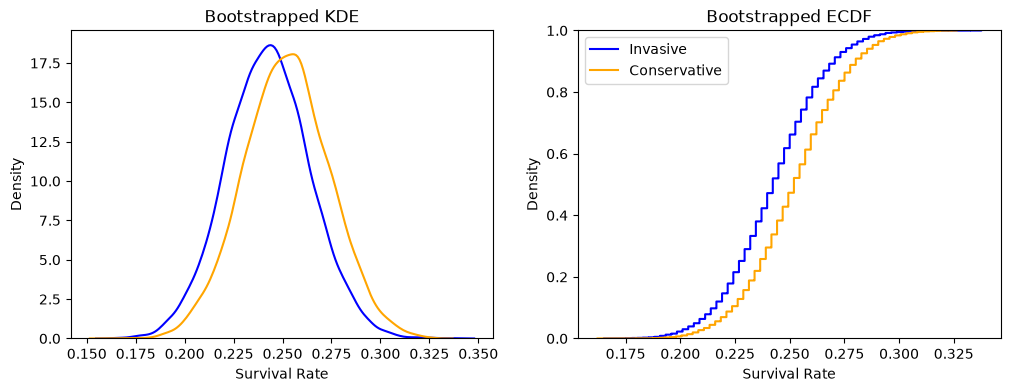

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

In [89]:
print('Bootstrap Mean Survival for Invasive : ',np.mean(outcome_a))
print('Bootstrap Mean Survival for Conservative : ',np.mean(outcome_b))
print('Bootstrap ATE : ',np.mean(ate))

print('Bootstrap Median Survival for Invasive : ',np.median(outcome_a))
print('Bootstrap Median Survival for Conservative : ',np.median(outcome_b))


Bootstrap Mean Survival for Invasive :  0.24261597938144333
Bootstrap Mean Survival for Conservative :  0.2521223650385604
Bootstrap ATE :  -0.009506385657117115
Bootstrap Median Survival for Invasive :  0.2422680412371134
Bootstrap Median Survival for Conservative :  0.2519280205655527


**Both the conservative and the invasive groups have similar distributions. This is indicated by the similar porportions of the curves in both the EDCF and the KDE plot. The convservative group is ever so slightly distributed around higher survival rates across the whole distribution, though the difference is very slight. This is indicated by the shift to the right on both the ECDF and the KDE plot for the conservative group, relative to the invasive group.**

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

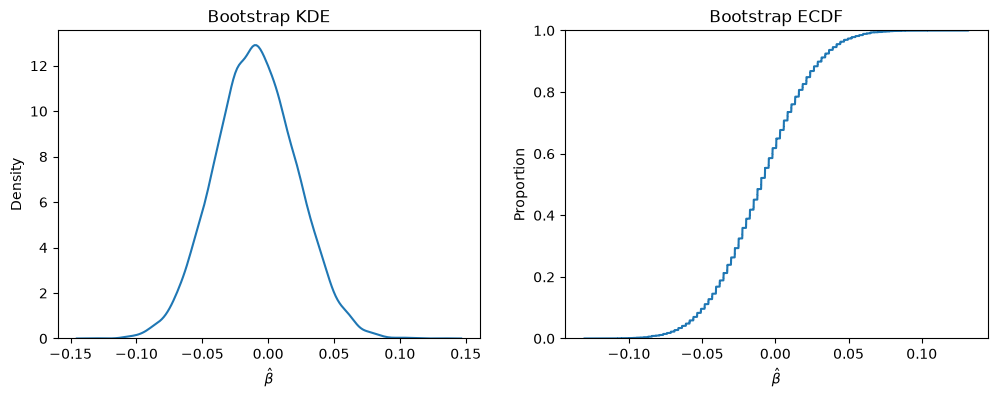

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


In [90]:
print(f'Range of values: ({min(ate)},{max(ate)})')


Range of values: (-0.13062173694113904,0.131860705483264)


**The average treatment effect appears to have a bell shaped normal density curve. It is centered around -0.01, which demonstrates that the average treatment affect is very commonly 0, and furthermore we do not know based on this distribution whether the average affect tends to be positive or negative. The range of values for the ATE are from -0.1  to 0.1, which does not give us any indication as to whether the balloon treatment tends to be helpful or harmful. Because 0 is essentially right in the middle, the effect of the treatment is appears to be nothing.**

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [8]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.05860917  0.04180691]
95% CI: [-0.0688522   0.05208322]
99% CI: [-0.08687356  0.07014427]


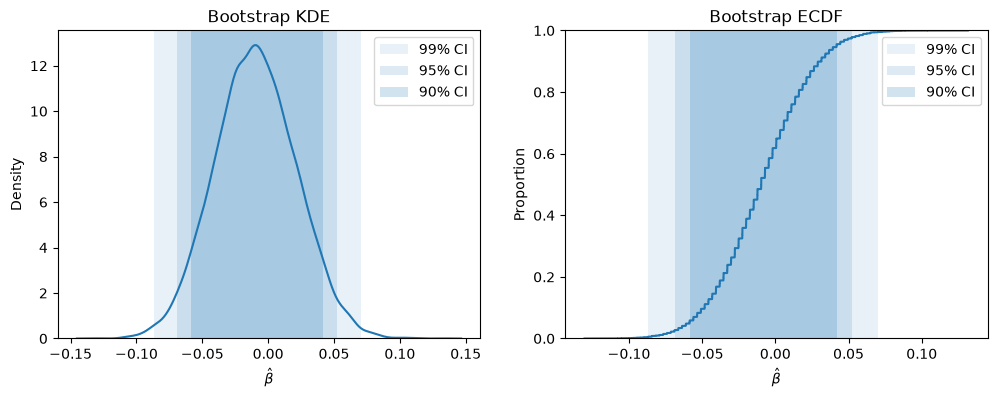

In [9]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**The 0 ATE value is right in the middle of all the confidence values, which means that under all of these confidence intervals we fail to reject the null hypothesis.**

**6.** What have we learned about inserting balloons into hearts?

**We have learned that there is no significant effect on patient survival from using the balloon technique. As a result, we would strongly advise against getting the balloon surgery on the premise that having an unhelpful and unnecessary invasive surgery is not worth the cost, pain, recovery time, risk of infection, etc.**

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

**Part 1**

In [10]:
df2 = pd.read_csv('./data/diabetes.csv')

In [11]:
df2 = df2.drop('Unnamed: 0', axis = 1)

In [12]:
df2['outcome'] = df2['outcome'].replace({'success': 1, 'failure': 0})

In [13]:
df2

,treatment,outcome
0,met,1
1,rosi,0
2,rosi,1
3,lifestyle,1
4,met,1
...,...,...
694,lifestyle,0
695,lifestyle,1
696,lifestyle,1
697,met,1


In [14]:
print(pd.crosstab( df2['treatment'], df2['outcome']), '\n')

outcome      0    1
treatment          
lifestyle  109  125
met        120  112
rosi        90  143 



In [15]:
print(f'Average outcome for the rosi treatment group: {np.round(df2.loc[ df2['treatment'] == 'rosi', 'outcome'].mean(), 3)}')
print(f'Average outcome for the met treatment group: {np.round(df2.loc[ df2['treatment'] == 'met', 'outcome'].mean(), 3)}')
print(f'Average outcome for the lifestyle treatment group: {np.round(df2.loc[ df2['treatment'] == 'lifestyle', 'outcome'].mean(), 3)}')

Average outcome for the rosi treatment group: 0.614
Average outcome for the met treatment group: 0.483
Average outcome for the lifestyle treatment group: 0.534


**The outcomes are above. It looks like rosi has the best average outcome for this sample, followed by lifestyle, then with met having the lowest average outcome.**

**Part 2**

In [16]:
#Set the number of resamples, R:
R = 10_000

#Subset the data:
rosi = df2.loc[ df2['treatment'] == 'rosi']
met = df2.loc[ df2['treatment'] == 'met']
life = df2.loc[ df2['treatment'] == 'lifestyle']

#Initiate empty lists that will record the resample means:
rosi_avgs = []
met_avgs = []
life_avgs = []

for i in range(R):
    #Create the resample for each group:
    rosi_boot = rosi.sample(frac=1.0, replace=True)
    met_boot = met.sample(frac=1.0, replace=True)
    life_boot = life.sample(frac=1.0, replace=True)

    #Calculate the mean of the resample and append it to the list:
    rosi_avgs.append(rosi_boot['outcome'].mean())
    met_avgs.append(met_boot['outcome'].mean())
    life_avgs.append(life_boot['outcome'].mean())

**Part 3**

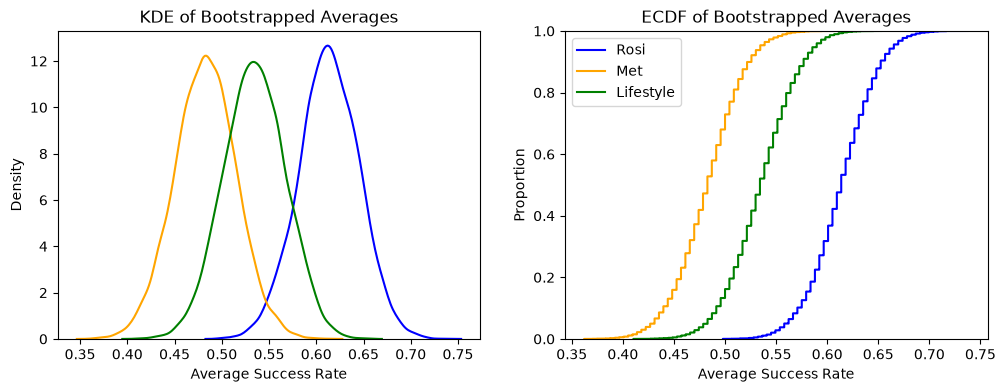

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(rosi_avgs, label='Rosi', color='blue', ax=ax[0])
sns.kdeplot(met_avgs, label='Met', color='orange', ax=ax[0])
sns.kdeplot(life_avgs, label='Lifestyle', color='green', ax=ax[0]).set(title='KDE of Bootstrapped Averages', xlabel='Average Success Rate', ylabel='Density')

sns.ecdfplot(rosi_avgs, label='Rosi', color='blue', ax=ax[1])
sns.ecdfplot(met_avgs, label='Met', color='orange', ax=ax[1])
sns.ecdfplot(life_avgs, label='Lifestyle', color='green', ax=ax[1]).set(title='ECDF of Bootstrapped Averages', xlabel='Average Success Rate', ylabel='Proportion')

plt.legend()
plt.show()

**Each of the three treatment groups appear to be normally distributed, as indicated by the bell shaped density curves and the s shapes distribution curves. The Rosi treatment group appears to have the highest average success rate across its distribution, followed by the Lifestyle treatment group, then by the Met treatment group.**

**Part 4**

met versus rosi, met versus lifestyle, rosi versus lifestyle

In [18]:
#Treatment of met minus treatment of rosi
met_min_rosi = df2.loc[ df2['treatment'] == 'met', 'outcome'].mean() \
    - df2.loc[ df2['treatment'] == 'rosi', 'outcome'].mean() 

#Treatment of met minus treatment of lifestyle
met_min_life = df2.loc[ df2['treatment'] == 'met', 'outcome'].mean() \
    - df2.loc[ df2['treatment'] == 'lifestyle', 'outcome'].mean() 

#Treatment of rosi minus treatment of lifestyle
rosi_min_life = df2.loc[ df2['treatment'] == 'rosi', 'outcome'].mean() \
    - df2.loc[ df2['treatment'] == 'lifestyle', 'outcome'].mean() 

In [19]:
print(f'Treatment of met minus treatment of rosi: {np.round(met_min_rosi,3)}')
print(f'Treatment of met minus treatment of lifestyle: {np.round(met_min_life,3)}')
print(f'Treatment of rosi minus treatment of lifestyle: {np.round(rosi_min_life,3)}')

Treatment of met minus treatment of rosi: -0.131
Treatment of met minus treatment of lifestyle: -0.051
Treatment of rosi minus treatment of lifestyle: 0.08


In [27]:
#Set the number of resamples, R:
R = 10_000

#Group the data into each treatment group:
rosi = df2.loc[ df2['treatment'] == 'rosi']
met = df2.loc[ df2['treatment'] == 'met']
life = df2.loc[ df2['treatment'] == 'lifestyle']

#Initiate empty lists that will record the resample means:
met_min_rosi_avgs = []
met_min_life_avgs = []
rosi_min_life_avgs = []

for i in range(R):
    #Create the resample for each treatment group:
    rosi_boot = rosi.sample(frac=1.0, replace=True)
    met_boot = met.sample(frac=1.0, replace=True)
    life_boot = life.sample(frac=1.0, replace=True)

    #Create the average treatment differences:
        #Treatment of met minus treatment of rosi
    boot_met_min_rosi = met_boot['outcome'].mean() - rosi_boot['outcome'].mean()
    
        #Treatment of met minus treatment of lifestyle
    boot_met_min_life = met_boot['outcome'].mean() - life_boot['outcome'].mean() 

        #Treatment of rosi minus treatment of lifestyle
    boot_rosi_min_life = rosi_boot['outcome'].mean() - life_boot['outcome'].mean() 

    #Append each value to the list:
    met_min_rosi_avgs.append(boot_met_min_rosi)
    met_min_life_avgs.append(boot_met_min_life)
    rosi_min_life_avgs.append(boot_rosi_min_life)

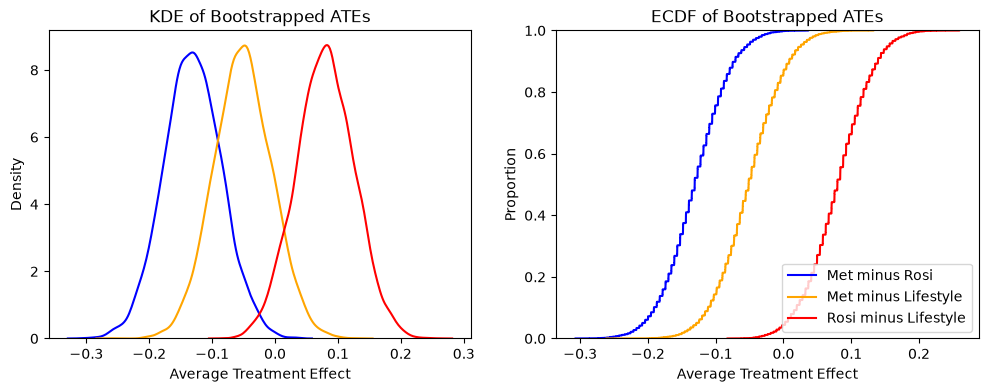

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(met_min_rosi_avgs, label='Met minus Rosi', color='blue', ax=ax[0])
sns.kdeplot(met_min_life_avgs, label='Met minus Lifestyle', color='orange', ax=ax[0])
sns.kdeplot(rosi_min_life_avgs, label='Rosi minus Lifestyle', color='red', ax=ax[0]).set(title='KDE of Bootstrapped ATEs', xlabel='Average Treatment Effect', ylabel='Density')

sns.ecdfplot(met_min_rosi_avgs, label='Met minus Rosi', color='blue', ax=ax[1])
sns.ecdfplot(met_min_life_avgs, label='Met minus Lifestyle', color='orange', ax=ax[1])
sns.ecdfplot(rosi_min_life_avgs, label='Rosi minus Lifestyle', color='red', ax=ax[1]).set(title='ECDF of Bootstrapped ATEs', xlabel='Average Treatment Effect', ylabel='Proportion')

plt.legend()
plt.show()

**Part 5**

In [57]:
#Create a function to calculate 90%, 95%, and 99% confidence intervals for a data set.
def ci_calulator(data):
    c_intervals = {'90% Confidence Interval' : np.quantile(data, [.05, .95]), 
                   '95% Confidence Interval' : np.quantile(data, [.025, .975]),
                    '99% Confidence Interval' :np.quantile(data, [.005, .995])}
    return c_intervals


In [58]:
print(f'Confidence intervels for the average treatment effect of Met and Rosi (Met Minus Rosi):')
ci_calulator(met_min_rosi_avgs)

Confidence intervels for the average treatment effect of Met and Rosi (Met Minus Rosi):


{'90% Confidence Interval': array([-0.2082285 , -0.05355557]),
 '95% Confidence Interval': array([-0.22127053, -0.04053204]),
 '99% Confidence Interval': array([-0.25551336, -0.01054444])}

In [59]:
print(f'Confidence intervels for the average treatment effect of Met and Lifestyle (Met Minus Lifestyle):')
ci_calulator(met_min_life_avgs)

Confidence intervels for the average treatment effect of Met and Lifestyle (Met Minus Lifestyle):


{'90% Confidence Interval': array([-0.12842986,  0.02578839]),
 '95% Confidence Interval': array([-0.14161509,  0.03894047]),
 '99% Confidence Interval': array([-0.17164033,  0.0690392 ])}

In [60]:
print(f'Confidence intervels for the average treatment effect of Rosi and Lifestyle (Rosi Minus Lifestyle):')
ci_calulator(rosi_min_life_avgs)

Confidence intervels for the average treatment effect of Rosi and Lifestyle (Rosi Minus Lifestyle):


{'90% Confidence Interval': array([0.00247606, 0.15654231]),
 '95% Confidence Interval': array([-0.01038113,  0.16949121]),
 '99% Confidence Interval': array([-0.03615064,  0.19522413])}

**The confidence intervals for the different average treatment effects show a significant difference between Met and Rosi at every level, with 0 being just barely outside the 90% interval. The negative values of these intervals means that Rosi has a larger average success rate than Met.**

**On the other hand, the confidence intervals for the average treatment effects between Met and Lifestyle interventions show an insignificant different at every level, as indicated by 0 being within each interval. Because of this, we cannot know whether if Met has a better or worse average treatment success rate compared to the Lifestyle intervention**

**Finally, the confidence interval for the average treatment effects between Rosi and Lifestyle just barely excludes 0 at 90% level, but includes 0 at the 95% and 99% level. Though the 90% interval technically means that Rosi has a statistically significant increase in average treatment success compared to Lifestyle at alpha = 0.1, I would hesitate to say that Rosi has better treatment outcomes than Lifestyle, given that the difference is not significant at the 95% nor the 99% interval.**

**Given these intervals, we can generally say that Rosi has better treatment outcomes than Met. However, the evidence that Rosi has better outcomes than Lifestyle is rather weak, being just barely supported at the 90% confidence level. Furthermore, we cannot conclude that Lifestyle has superior outcomes to Met.** 

In [ ]:
success_rate = df2.groupby('treatment').mean()
success_rate

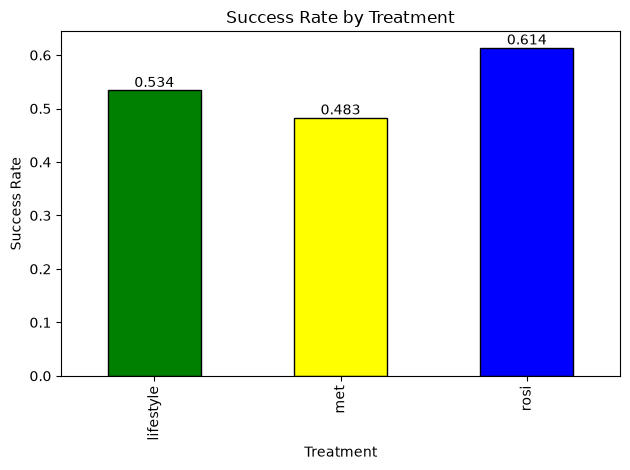

In [88]:
ax = success_rate['outcome'].plot(kind='bar', color=['green', 'yellow', 'blue'], edgecolor='black')
ax.set_ylabel('Success Rate')
ax.set_xlabel('Treatment')
ax.set_title('Success Rate by Treatment')

for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')

plt.tight_layout()
plt.show()

**Part 6: Write-up**

Our team analyzed three treatment interventions for patients suffering from pre-diabetes; these were Metformin ("met"), Rosiglitazone ("rosi"), and lifestyle adjustments such as midified diet and exercise ("lifestyle"). A successful treatment was defined by whether the patient with pre-diabetes went on to develop full blown diabetes -- i.e., a failed treatment -- or whether they did not develop full blown diabetes -- a success. We compared the different treatments using average treatment effect (ATE), and we found that Rosiglitazone has a reliably higher success rate than Metformin across multiple resamples, whereas lifestyle adjustment is a viable non-medicative alternative to both.

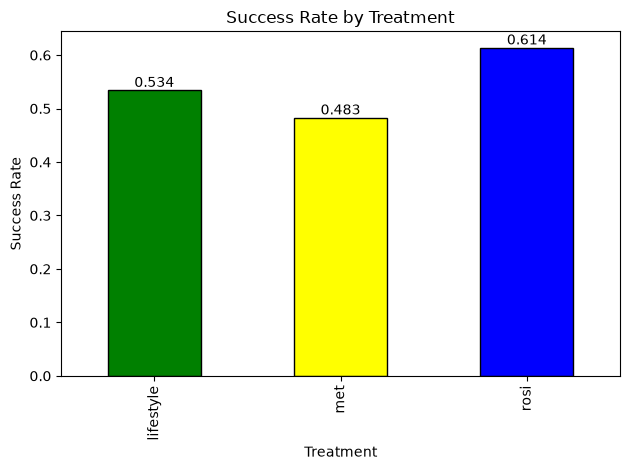

Roughly 230 patients were assigned to each treatment group on a random basis, and 'success' for each patient was described using yes/no categorical variable. As shown in the above plot, we found that the Rosi treatment group had the highest success rate, followed by lifestyle adjustments, then Met. We bootstrapped each treatment arm separately, and for each bootstrap resample, we calculated the difference in average success rate between each pairwise combination of the three groups. This difference yeilded the average treatment effect (ATE) comparing each of the three groups to the others. Because each patient was assigned to a group randomly, the ATE is an unbiased estimator of the true difference in treatment effects. The distribution of ATE's for each pairwise combination of treatment groups is shown below. Using the ATE's, we can compare the different treatments.

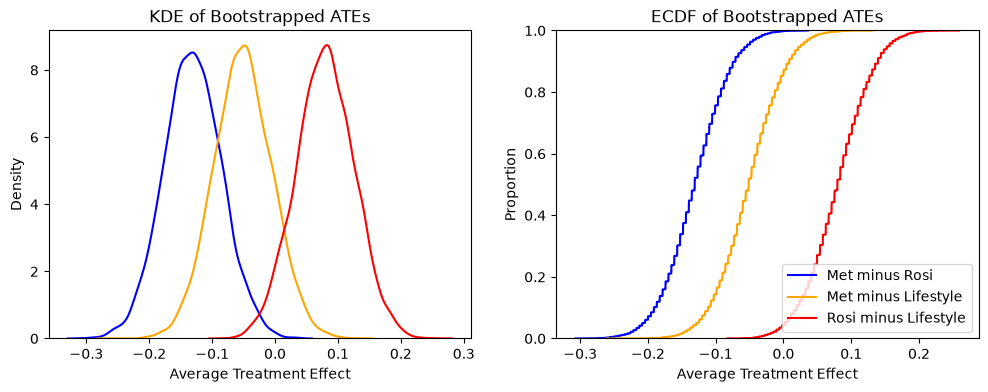

As seen in the above plot, the ATE between Met and Rosi (in blue) is distributed furthest from 0, suggesting that the Rosi treatment results in higher success rates than Met. In contrast, the ATE between Met and lifestyle adjustments (in yellow) is distributed more evenly about 0, suggesting that Met is not significantly more effective than lifestyle adjstments. To make more definitive comparisons, we determined confidence intervals at the 90%, 95%, and 99% levels for each pairwise ATE. The confidence intervals for Met-Rosi ATE are shown below: because 0 is excluded from the interval at every level, we conclude that Rosi yields a higher treatment success rate than Met. 

| Confidence Level | Confidence Interval (Rosi-Met ATE) |
|---|---|
| 90% | -0.2082, -0.0536 |
| 95% | -0.2213, -0.0405 |
| 99% | -0.2555, -0.0105 |


Lifestyle adjustments offer an intriguing alternative to medication for treatment of pre-diabtetes. The raw sample average success for lifestyle adjustments were slightly larger than Met (53% compared to 48%) and slightly lesser than Rosi (at 61%). At the 90% confidence level, however, we found that Lifestyle was not significantly more effective than Met. At this level, Lifestyle was significantly less effective than Rosi, but under higher levels of confidence, this difference was not significant. The confidence intervals for Rosi-Lifestyle ATE are shown below; note that 0 is included at the 95% and 99% level. 

| Confidence Level | Confidence Interval (Rosi-Lifestyle ATE) |
|---|---|
| 90% | 0.0025, 0.1565 |
| 95% | -0.0104, 0.1695 |
| 99% | -0.0362, 0.1952 |

In summary, we find that Rosi has a significantly greater average treatment success rate than Met at 95% confidence, and that Lifestyle does not have a significantly different success rate than Met or Rossi at the 95% level. We therefore recommend dropping Met from the study, and to move forward with Rossi and Lifestyle as candidates for further study. Even if Rossi is found to have superior success rates than Lifestyle, we believe that behavioral lifestyle changes should remain a candidate for study as a non-medicative intervention, and as a useful benchmark against which medications may be judged.